# Dynamic-range-aware reconstruction demo

This notebook runs the pretrained model on the simulated AD_LTEM test region, shows the input representations of a diffraction pattern, evaluates patches, and stitches the complete 12 x 12 test region.

Generate the data first with `python main.py --mode generate`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt

from datasets import load_ad_ltem_test_set
from models import Calibration
from utils import (
    AdaptiveImageStitcher,
    disable_tf32,
    evaluate_reconstruction,
    format_average_metrics,
    format_metrics,
    load_pretrained_model,
    plot_global_stitching,
    plot_input_representations,
    plot_patch_comparison,
    reconstruct_patches,
    select_device,
)

In [2]:
ROOT = Path.cwd()
CHECKPOINT = ROOT / 'checkpoints' / 'ad_ltem' / 'model.pth'
ASSETS = ROOT / 'assets'

disable_tf32()
device = select_device()
test_data = load_ad_ltem_test_set(ROOT, grid_size=12)
model, checkpoint = load_pretrained_model(CHECKPOINT, device=device)
calibration = Calibration(**checkpoint['calibration'])
amp_pred, phase_pred = reconstruct_patches(
    model,
    test_data.diffraction,
    checkpoint['amplitude_range'],
    checkpoint['phase_range'],
    batch_size=64,
    device=device,
)

stitcher = AdaptiveImageStitcher(point_size=8, overlap=5 * 8)
result = evaluate_reconstruction(
    test_data,
    amp_pred,
    phase_pred,
    checkpoint['amplitude_range'],
    checkpoint['phase_range'],
    stitcher,
)

print(f'Device: {device}')
print(f"Representation: {checkpoint['representation']}")
print(f'Calibration: g_l = {calibration.low_gain:.3f}, g_h = {calibration.high_gain:.2f}, r_d = {calibration.disc_radius} px')
print(f'All {len(test_data.diffraction)} AD_LTEM patches (mean ± std)')
print(f"Amplitude: {format_average_metrics(result['patch']['amplitude'])}")
print(f"Phase:     {format_average_metrics(result['patch']['phase'])}")

Device: cuda
Representation: dc_dre
Calibration: g_l = 3.527, g_h = 25.59, r_d = 1.5 px
All 144 AD_LTEM patches (mean ± std)
Amplitude: MSE 3.828e-02 ± 2.992e-02 | MAE 4.287e-02 ± 3.142e-02 | SSIM 0.8415 ± 0.1311 | PSNR 16.24 ± 5.68 dB
Phase:     MSE 8.816e-03 ± 5.148e-03 | MAE 6.986e-02 ± 2.714e-02 | SSIM 0.7286 ± 0.1125 | PSNR 17.82 ± 3.07 dB


## Input representations

The same diffraction pattern as seen by the encoders. The low-gain view keeps the bright central disc in range; the high-gain view saturates the disc and stretches the weak high-angle signal.

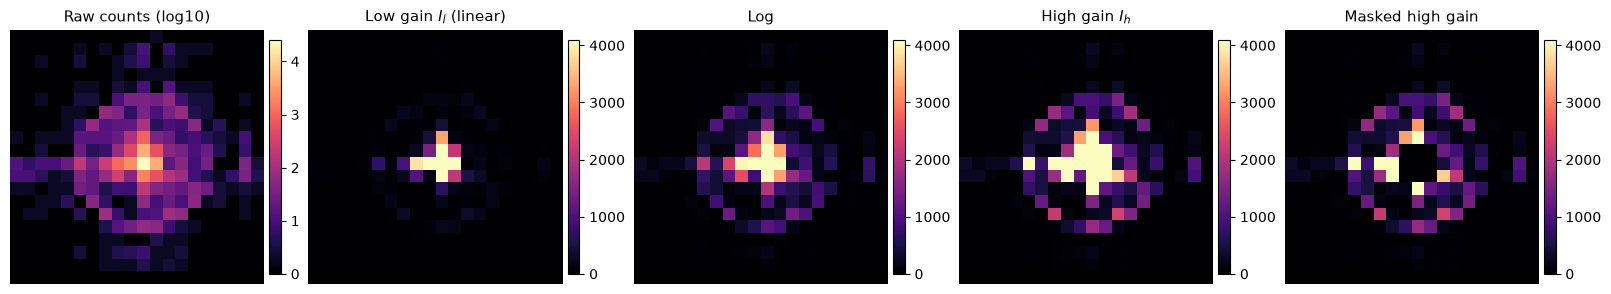

In [3]:
representation_figure = plot_input_representations(
    test_data.diffraction[79],
    calibration,
    save_path=ASSETS / 'input_representations.png',
)
plt.show()

## Patch reconstruction

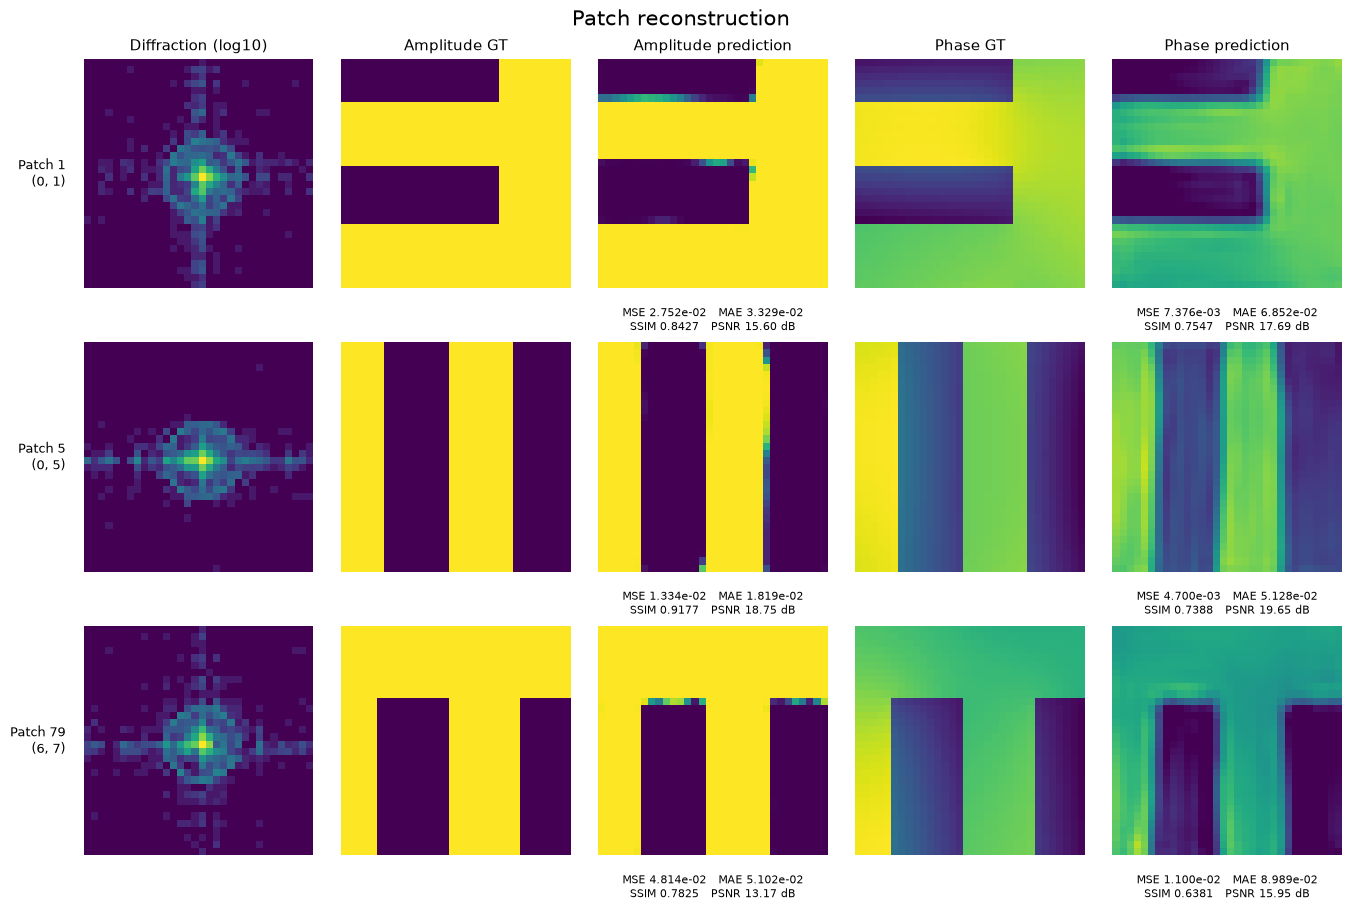

In [4]:
patch_figure, patch_results = plot_patch_comparison(
    test_data.diffraction,
    test_data.amplitude,
    amp_pred,
    test_data.phase,
    phase_pred,
    checkpoint['amplitude_range'],
    checkpoint['phase_range'],
    indices=(1, 5, 79),
    grid_size=test_data.grid_size,
    save_path=ASSETS / 'patch_comparison.png',
)
plt.show()

## Global stitching

In [5]:
images = result['images']
print(f"Global shape: {images['amplitude_true'].shape}")
print(f"Amplitude: {format_metrics(result['stitched']['amplitude'])}")
print(f"Phase:     {format_metrics(result['stitched']['phase'])}")

Global shape: (96, 96)
Amplitude: MSE 1.241e-02   MAE 3.423e-02 | SSIM 0.8413   PSNR 19.06 dB
Phase:     MSE 4.893e-03   MAE 5.579e-02 | SSIM 0.8111   PSNR 19.45 dB


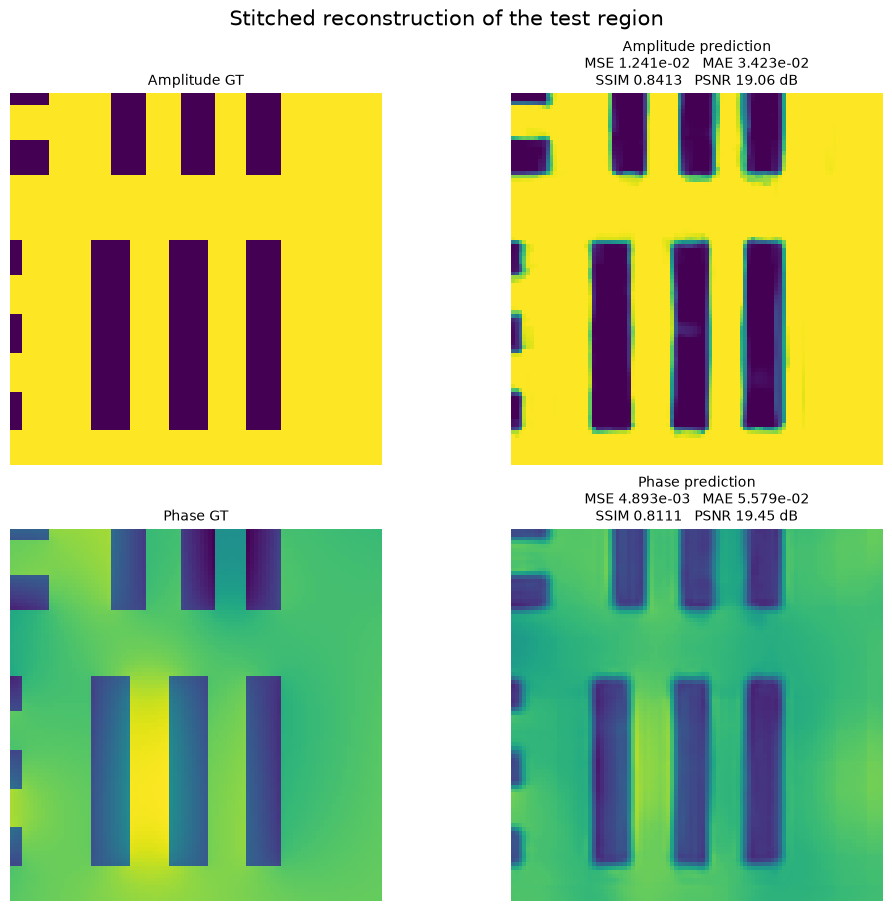

In [6]:
global_figure = plot_global_stitching(
    images['amplitude_true'],
    images['amplitude_pred'],
    images['phase_true'],
    images['phase_pred'],
    result['stitched']['amplitude'],
    result['stitched']['phase'],
    save_path=ASSETS / 'global_stitching.png',
)
plt.show()